# Marketing Campaign Lab - step-by-step project notebook

**Business Analytics Workshop | CookieSensei Labs | Python 3.12**

Work through **what we are doing, why it is useful, how the code works, and what its output means**. The explanations are Markdown cells, and the analysis is in editable Python code cells with saved results. All records are fictional teaching data; monetary values are INR.

Keep this notebook with [marketing_campaigns.csv](marketing_campaigns.csv) and [app.py](app.py). The [Markdown companion](EXPLANATION.md) provides a continuous reading version. The source application and data used here match revision `c10a61c36fffdd048b69dd78926e6663bc986fce`.

## Your notebook learning route

Connect each marketing question to a calculation with an appropriate denominator. Your objectives:

- Explain the difference between impressions, clicks, conversions, spend and attributed revenue.
- Trace a metric from selected observations to totals and then to a ratio.
- Compare channel efficiency with the volume and spending behind it.
- Describe how the same pipeline drives the controls and results in [app.py](app.py).

### Know what a row represents

One source row is a channel/campaign observation for one day. Several observations can share a date. A daily trend combines the selected observations for each date before drawing its points.

The CSV already contains conversions and attributed revenue. Your calculations summarize those supplied values. The table does not identify unique new customers or provide the attribution method. Keep asking: **“What exactly is being counted, and what is the denominator?”** This matters when interpreting acquisition cost or recommending budgets.

### Give each tool a clear job

| Tool | Its job in this lesson | What you should inspect |
| --- | --- | --- |
| Python and `Path` | Locate the input and express the sequence of calculations | File location and variable names |
| pandas | Load, type, select, aggregate, calculate ratios and export tables | Grain, totals and denominators |
| Plotly Express | Draw the daily trend, channel ROAS bars and observation scatter | Whether each mark represents a date, channel or observation |
| Matplotlib and Seaborn | Draw the spend histogram and conversion boxplot | The observations behind a distribution |
| Streamlit | Connect user choices to browser controls, charts and downloads | Which outputs share the selected population |

Why pandas? The business questions repeat operations across named columns, groups and dates. A DataFrame keeps the labels, types and rows together. It lets you make a row selection explicit, sum the selected counts and amounts, and divide aligned group totals. This makes the reasoning inspectable. Pandas cannot choose the right denominator or decide that attributed revenue is incremental revenue; those are analytical judgments.

### Work with the kernel deliberately

The kernel remembers variables between executions. `frame` is the typed source table, `filtered` is the selected population, `channel_summary` is one row per represented channel, and `spend` is a scalar total. The workflow is **observe → select → sum → divide → compare → explain**. Aggregating before dividing is central to the overall funnel and return metrics.

Run the analysis cells in numbered order. After editing a selection, rerun its dependent cells: existing outputs otherwise describe an older selection. Restart the kernel and rerun the analysis to expose forgotten interactive state.

## How to work through this notebook

1. Open `TUTORIAL.ipynb` in JupyterLab or VS Code and select the workshop's Python 3.12 environment.
2. Read the question above a code cell, predict the result, then use **Shift+Enter** to run that cell.
3. Run cells from top to bottom. Python variables stay in the kernel's memory; changing an earlier cell requires rerunning the cells that depend on it.
4. Compare the output with the interpretation underneath. Try the checkpoints before moving on.
5. Use **Restart Kernel and Run All Cells** to reproduce the baseline from a clean session. All executable cells here finish without launching a long-running web server.

The first code cell locates this project and configures notebook chart display. It supports starting in the project folder, the workshop folder, or the repository root. It changes only the kernel's working directory; it does not move any files.

The complete Streamlit teaching script later in this notebook is a **reference code block in a Markdown cell**. Copy it into the stated separate `.py` file to launch its browser interface. The runnable `AppTest` section independently inspects the existing `app.py` and demonstrates a filter rerun inside the notebook. These two execution contexts are explained separately.

Saved figure outputs include embedded PNG previews. In a running JupyterLab or VS Code notebook, Plotly can also display interactive figures. A GitHub preview shows the saved notebook and cannot execute Python. Keep the CSV and app beside the notebook when downloading it for execution. Local JupyterLab users can install the notebook interface with `python -m pip install jupyterlab`; the prepared Cloud Lab already supplies it. Analysis package versions are listed in the [workshop setup](../README.md).

In [1]:
from pathlib import Path                  # Represent a folder or filename as a Python object.
import os                                # Change this kernel's working directory when necessary.
import sys                               # Inspect the Python version selected by the kernel.
from IPython.display import display      # Render tables and figures as notebook outputs.
import matplotlib
import plotly.io as pio

# Support opening the notebook from this folder, the workshop, or the repo root.
notebook_start = Path.cwd()
candidate_folders = [
    notebook_start,
    notebook_start / '02_marketing_campaigns',
    notebook_start / 'business_analytics_workshop' / '02_marketing_campaigns',
]
PROJECT_DIR = next(
    (folder for folder in candidate_folders
     if (folder / 'marketing_campaigns.csv').is_file() and (folder / 'app.py').is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Open this notebook with its sibling CSV and app.py in the project folder.')
PROJECT_DIR = PROJECT_DIR.resolve()
os.chdir(PROJECT_DIR)

# Inline figures belong below their code cells; the Plotly renderer is used by JupyterLab/VS Code.
matplotlib.use('module://matplotlib_inline.backend_inline')
pio.renderers.default = 'plotly_mimetype'
print('Project folder:', PROJECT_DIR.name)
print('CSV and app.py found.')
print('Python:', sys.version.split()[0])

Project folder: 02_marketing_campaigns
CSV and app.py found.
Python: 3.12.14


### Python vocabulary you will use repeatedly

| Code pattern | What it means | Why it appears here |
| --- | --- | --- |
| `name = expression` | Calculate a value and give it a name | Later cells can reuse the result |
| `import pandas as pd` | Import a library with a short alias | `pd.read_csv(...)` calls its CSV reader |
| `frame["column"]` | Select one named column as a Series | Apply a calculation to that measure |
| `frame[mask]` | Keep rows whose Boolean condition is `True` | Define the population being analyzed |
| `.method(...)` | Ask an object to perform an operation | `.sum()`, `.mean()` and `.groupby()` answer different questions |
| `# explanation` | A comment Python does not execute | Describe the purpose of the next operation |
| `f"...{value:.2f}..."` | Put a formatted value into a string | Communicate results without changing the underlying value |

Indentation groups statements inside a `for`, `if`, function or `with` block. Brackets, parentheses and column spelling matter. When a cell fails, read the final error message, inspect the named variable or column, and fix the earliest failed step before continuing.

## The business problem

A marketing team has a limited advertising budget. One channel attracts many clicks, another produces more conversions, and a third may report a high revenue-to-spend ratio at a tiny scale. Which result should the team investigate before changing its budget?

The quantities answer different questions. Impressions measure ad displays. Clicks measure recorded interactions. Conversions measure attributed outcome events. Spend measures advertising cost, and revenue is the amount already attributed to those observations. The app needs to compare these quantities using the right denominator, not merely find the largest number or average daily percentages.

The solution is a reproducible descriptive workflow: select channels/campaigns/dates, calculate totals and appropriate ratios, compare efficiency with scale, inspect distributions and individual observations, and document the selected evidence. Its useful outcome is a focused investigation or controlled budget experiment. A chart does not prove that moving money to a high-ROAS channel will preserve that return.

This project does not call an advertising API, change budgets, identify unique new customers, train a model, calculate net profit or implement an attribution algorithm. It accepts `revenue` and `conversions` already present in the CSV. Accurately summarizing attributed results is different from proving that an advertisement caused additional sales.

## Environment and the role of each library

Use Python 3.12 with the versions in the [workshop README](../README.md):

```bash
python -m pip install streamlit==1.50.0 pandas==2.2.3 numpy==2.3.5 matplotlib==3.10.8 seaborn==0.13.2 plotly==6.5.2
```

Use your prepared environment or a virtual environment. For a full repository clone on Windows, follow the root README's WSL/Linux guidance because other phase-folder names contain `>` characters. No API key or database is needed by this project.

**Why pandas?** The input is a table and the questions require table operations. A pandas **DataFrame** stores rows, named columns, types and a row index. One selected column is usually a **Series**. Pandas provides CSV parsing, conversion, Boolean selection, grouping, aggregation and export. Python could implement those operations with loops and dictionaries, but the concise pandas form lets the business rule remain visible. It still needs the analyst to choose the correct grain and denominator.

`Path` handles file locations. Matplotlib creates figures/axes and draws the spend histogram. Seaborn draws the conversion boxplot. Plotly Express creates the interactive daily trend, ROAS bar chart and observation scatter plot. Streamlit adds browser controls, containers, tables and downloads. NumPy is part of the environment but is not directly imported by this source app.

In chart cells, `display(fig)` renders the figure below the code. Matplotlib cells then call `plt.close(fig)` to release the figure handle while preserving the displayed output. Each image below is the saved result of that displayed figure. The static PNG does not reproduce Plotly's live hover and zoom controls; those are available in a live notebook or Streamlit view.

## Part 1 - Load and understand campaign observations

### Step 01 - Read the actual CSV into a DataFrame

**Question:** What is the actual size and structure of our input?

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

# Notebook cells use the project working directory; the CSV must be here.
DATA_FILE = Path("marketing_campaigns.csv")
frame = pd.read_csv(DATA_FILE)  # Header names become DataFrame columns.
print(f"Loaded {frame.shape[0]} observations and {frame.shape[1]} columns.")
print("Source file:", DATA_FILE.name)

Loaded 360 observations and 8 columns.
Source file: marketing_campaigns.csv


**Interpretation and reasoning**

The 360 rows are campaign observations, not 360 customers or 360 days. `shape` returns the table dimensions. In the existing script, `Path(__file__).resolve().with_name(...)` locates the CSV beside `app.py`. A notebook normally has no `__file__`, so this teaching cell deliberately uses its current project folder. The alias `pd` shortens the name pandas; it does not alter library behavior.

### Step 02 - Inspect real records and understand their grain

**Question:** What exactly does one row represent?

In [3]:
# Display the first five source observations without the internal row index.
print(frame.head(5).to_string(index=False))

      date channel campaign  impressions  clicks  conversions   spend  revenue
2025-01-01  Search Seasonal        14074     984           96 6793.68 94378.06
2025-01-01  Social   Launch        17118     501           33 2065.35 14977.08
2025-01-01   Email Seasonal         9956     254           26 1385.10 23334.97
2025-01-01 Display   Launch         5478     369           17 1610.06 15077.95
2025-01-02  Search Seasonal         3926     132            4 1062.78  1864.03


### Notebook skill - inspect a table directly

The printed preview above is useful in scripts and text reports. A notebook can also render the DataFrame itself as a table. `head(5)` returns a small view for inspection; it does not replace the full source table. Compare the row labels on the left with any business identifier column.

In [4]:
# Display the same source as a notebook table; keep frame unchanged.
display(frame.head(5))

,date,channel,campaign,impressions,clicks,conversions,spend,revenue
0,2025-01-01,Search,Seasonal,14074,984,96,6793.68,94378.06
1,2025-01-01,Social,Launch,17118,501,33,2065.35,14977.08
2,2025-01-01,Email,Seasonal,9956,254,26,1385.10,23334.97
3,2025-01-01,Display,Launch,5478,369,17,1610.06,15077.95
4,2025-01-02,Search,Seasonal,3926,132,4,1062.78,1864.03


**Interpretation and reasoning**

One row is one channel/campaign observation for one day. The same date, channel and campaign label can appear repeatedly across the file's combinations. Impressions and clicks are events, not unique people. Conversions are attributed events, not verified first-time customer acquisitions. Spend and revenue are INR amounts already recorded in the source. Unlike the retail project, this app does not calculate revenue from quantity and price.

### Step 03 - Parse dates and explicitly require numeric measures

**Question:** Why do types matter before calculating a rate?

In [5]:
print("Date type before conversion:", frame["date"].dtype)

# Parsed dates support chronological comparison and date grouping.
frame["date"] = pd.to_datetime(frame["date"], errors="raise")
numeric_columns = ["impressions", "clicks", "conversions", "spend", "revenue"]
for column in numeric_columns:
    # Invalid text raises an error instead of silently turning into a zero.
    frame[column] = pd.to_numeric(frame[column], errors="raise")

print("\nTypes after conversion:")
print(frame.dtypes.to_string())

Date type before conversion: object

Types after conversion:
date           datetime64[ns]
channel                object
campaign               object
impressions             int64
clicks                  int64
conversions             int64
spend                 float64
revenue               float64


**Interpretation and reasoning**

`frame['clicks']` is a Series; assigning its converted version back replaces that column's representation. Counts and money must support arithmetic, and dates must support date operations. Parsing only checks whether values can be represented in those types. It does not enforce nonnegative whole counts, finite amounts or consistent attribution definitions. The source catches loading/conversion failures and shows a Streamlit error; a notebook normally displays the Python exception directly.

### Step 04 - Validate required inputs and inspect quality

**Question:** Are the essential columns present, and might observations be counted twice?

In [6]:
required_columns = ["date", "channel", "campaign", "impressions",
                    "clicks", "conversions", "spend", "revenue"]
if not set(required_columns).issubset(frame.columns):
    raise ValueError("The CSV is missing required columns.")
if frame.empty:
    raise ValueError("The CSV contains no observations.")
if frame[required_columns].isna().any().any():
    raise ValueError("Fill missing required analysis values first.")

# Summarize the whole loaded source, not a later filtered subset.
quality = pd.DataFrame({
    "column": frame.columns,
    "type": frame.dtypes.astype(str).values,
    "missing": frame.isna().sum().values,
})
print(quality.to_string(index=False))
print("Exact duplicate rows:", int(frame.duplicated().sum()))
print("Repeated date/channel/campaign combinations:",
      int(frame.duplicated(["date", "channel", "campaign"]).sum()))

     column           type  missing
       date datetime64[ns]        0
    channel         object        0
   campaign         object        0
impressions          int64        0
     clicks          int64        0
conversions          int64        0
      spend        float64        0
    revenue        float64        0
Exact duplicate rows: 0
Repeated date/channel/campaign combinations: 0


**Interpretation and reasoning**

The first `.any()` reduces missingness by column; the second asks whether any required field contains a missing value. The bundled data passes. The repeated-combination check is an extra teaching inspection: the existing app reports exact duplicates but does not enforce a unique date/channel/campaign key. It also does not remove duplicate observations automatically. A complete, parseable row can still be wrong, duplicated in business meaning or measured under a different attribution window.

### Step 05 - Check the date coverage and what repeats

**Question:** Does a daily observation represent an entire company's daily budget?

In [7]:
print("Observed dates:", frame["date"].min().date(), "to", frame["date"].max().date())
print("Distinct dates:", frame["date"].nunique())

# Count observations by channel and campaign, rather than counting customers.
print("\nObservations by channel:")
print(frame.groupby("channel").size().rename("observations").to_string())
print("\nObservations by campaign label:")
print(frame.groupby("campaign").size().rename("observations").to_string())

daily_counts = frame.groupby("date").size()
print("\nMinimum/maximum observations per date:", daily_counts.min(), daily_counts.max())

Observed dates: 2025-01-01 to 2025-03-31
Distinct dates: 90

Observations by channel:
channel
Display    90
Email      90
Search     90
Social     90

Observations by campaign label:
campaign
Always on    121
Launch       100
Seasonal     139

Minimum/maximum observations per date: 4 4


**Interpretation and reasoning**

This file has four channel observations per date over 90 dates, January-March 2025. One raw row is therefore not a complete company-day total. A histogram of raw spend answers a different question from a line chart of spend summed by date. Campaign labels are repeated categories, not unique customer identities. These counts describe the bundled file; the code does not promise another CSV will have exactly four observations every day.

## Part 2 - Filter and calculate weighted marketing metrics

### Step 06 - Turn channel, campaign and date choices into selected rows

**Question:** How do filter choices control the numbers that follow?

In [8]:
# Use the source app's default: all channels, all campaigns, full observed dates.
selected_channels = sorted(frame["channel"].unique())
selected_campaigns = sorted(frame["campaign"].unique())
dates = (frame["date"].min().date(), frame["date"].max().date())

filtered = frame.copy()
filtered = filtered[filtered["channel"].isin(selected_channels)]
filtered = filtered[filtered["campaign"].isin(selected_campaigns)]
filtered = filtered[filtered["date"].dt.date.between(dates[0], dates[1])]
if filtered.empty:
    raise ValueError("No observations match this selection.")

print(f"Selected {len(filtered)} of {len(frame)} observations.")
print(f"Requested dates: {dates[0]} to {dates[1]} (inclusive)")

# Show a real narrower mask without changing the main analysis population.
search_mask = frame["channel"].isin(["Search"])
print("Rows a Search-only selection would keep:", int(search_mask.sum()))

Selected 360 of 360 observations.
Requested dates: 2025-01-01 to 2025-03-31 (inclusive)
Rows a Search-only selection would keep: 90


**Interpretation and reasoning**

`.isin()` returns one Boolean per row and the outer brackets keep the True rows. Each successive filter narrows the current selection, so the conditions combine as AND. The date interval is inclusive. The main tutorial retains all default observations so the generated results match the original app's initial view. The Search mask is a separate demonstration. In the app, controls read their available labels from full `frame`; a combination with no records triggers a helpful stop rather than a misleading empty ranking.

### Checkpoint - Predict what the totals include

Before adding columns, name the retained channels, campaigns and dates. Predict whether counting rows would equal counting days. Inspect both quantities, then explain why impressions, clicks and conversions must be added from their columns rather than inferred from the row count.

### Step 07 - Add the selected funnel counts and monetary amounts

**Question:** What activity and money do the selected records represent?

In [9]:
# Sum additive quantities first. Each total covers exactly the selected rows.
impressions = filtered["impressions"].sum()
clicks = filtered["clicks"].sum()
conversions = filtered["conversions"].sum()
spend = filtered["spend"].sum()
revenue = filtered["revenue"].sum()

print(f"Impressions: {impressions:,}")
print(f"Clicks: {clicks:,}")
print(f"Conversions: {conversions:,}")
print(f"Ad spend: INR {spend:,.2f}")
print(f"Attributed revenue: INR {revenue:,.2f}")

Impressions: 3,484,268
Clicks: 146,788
Conversions: 11,634
Ad spend: INR 2,431,713.93
Attributed revenue: INR 8,338,864.84


**Interpretation and reasoning**

These totals are the numerators and denominators for the next step. A total spend answers 'how much cost in this selection?', not 'how efficient was it?'. More days or more selected channels can produce larger totals without better performance. Revenue is already attributed by the dataset; the app does not reconstruct individual transactions or determine whether the advertisement caused them.

### Step 08 - Calculate CTR, conversion rate, CPA and ROAS

**Question:** Which denominator answers each business question?

In [10]:
def ratio(numerator, denominator):
    # Match the source helper: zero denominators use a scalar fallback.
    return numerator / denominator if denominator else 0.0

ctr = ratio(clicks, impressions)         # Clicks per ad display.
conversion_rate = ratio(conversions, clicks)  # Conversions per recorded click.
roas = ratio(revenue, spend)             # Attributed revenue per INR ad spend.
cpa = ratio(spend, conversions)         # INR ad spend per attributed conversion.

print(f"Click-through rate: {ctr:.2%}")
print(f"Click-to-conversion rate: {conversion_rate:.2%}")
print(f"ROAS: {roas:.2f}x")
print(f"Cost per attributed conversion: INR {cpa:,.2f}" if conversions else "CPA: N/A")

Click-through rate: 4.21%
Click-to-conversion rate: 7.93%
ROAS: 3.43x
Cost per attributed conversion: INR 209.02


**Interpretation and reasoning**

CTR normalizes clicks by impressions; conversion rate normalizes conversions by clicks. They describe different funnel stages. ROAS is a multiple: 3.43x means about INR 3.43 attributed revenue per INR 1 of advertising spend, not INR 3.43 profit. CPA uses conversion events, so it is not proven distinct-new-customer acquisition cost. `:.2%` turns a fraction into a percentage for display; the `x` suffix is a ratio label. The source gives CPA an explicit N/A display when there are no conversions; other helper-based rates may display a fallback zero for an undefined denominator.

### Checkpoint - Predict the effect of unequal scale

Imagine one observation has much more spend than another. Should they influence total ROAS equally? Inspect the comparison of mean observation ratios with the ratio of totals. Explain why the weights for ROAS and click-to-conversion rate come from different columns.

### Step 09 - Prove why averaging observation percentages gives a different answer

**Question:** Why does the existing app calculate ratios from summed inputs?

In [11]:
# This extra inspection calculates individual-observation rates for teaching.
row_roas = filtered["revenue"].div(filtered["spend"].replace(0, float("nan")))
row_cvr = filtered["conversions"].div(filtered["clicks"].replace(0, float("nan")))

# Correct weights follow the denominator: spend for ROAS, clicks for conversion rate.
weighted_roas = (row_roas * filtered["spend"] / spend).sum()
weighted_cvr = (row_cvr * filtered["clicks"] / clicks).sum()

print(f"Unweighted mean of observation ROAS: {row_roas.mean():.4f}x")
print(f"Spend-weighted observation ROAS:     {weighted_roas:.4f}x")
print(f"Total revenue / total spend:        {roas:.4f}x")
print()
print(f"Unweighted mean observation conversion rate: {row_cvr.mean():.4%}")
print(f"Click-weighted observation conversion rate:  {weighted_cvr:.4%}")
print(f"Total conversions / total clicks:           {conversion_rate:.4%}")

Unweighted mean of observation ROAS: 4.3989x
Spend-weighted observation ROAS:     3.4292x
Total revenue / total spend:        3.4292x

Unweighted mean observation conversion rate: 7.8352%
Click-weighted observation conversion rate:  7.9257%
Total conversions / total clicks:           7.9257%


**Interpretation and reasoning**

A tiny observation should not receive equal influence to a large one when the question is overall return per rupee or conversion per click. In the bundled positive-denominator data, weighting each observation's rate by its denominator produces the same result as dividing totals. The simple average answers the average rate of an equally chosen observation, a different question. The source directly divides totals rather than creating these row-rate columns. This demonstration uses the real CSV and does not add fields to `filtered`.

### Step 10 - Trace the first actual observation by hand

**Question:** Can we connect a displayed rate to concrete source numbers?

In [12]:
# iloc[0] retrieves one source observation by its row position.
observation = filtered.iloc[0]
print(f"{observation['date']:%Y-%m-%d} | {observation['channel']} | {observation['campaign']}")
print(f"CTR = {observation['clicks']} / {observation['impressions']} = "
      f"{ratio(observation['clicks'], observation['impressions']):.2%}")
print(f"Conversion rate = {observation['conversions']} / {observation['clicks']} = "
      f"{ratio(observation['conversions'], observation['clicks']):.2%}")
print(f"CPA = INR {observation['spend']:.2f} / {observation['conversions']} = "
      f"INR {ratio(observation['spend'], observation['conversions']):.2f}")
print(f"ROAS = INR {observation['revenue']:.2f} / INR {observation['spend']:.2f} = "
      f"{ratio(observation['revenue'], observation['spend']):.2f}x")

2025-01-01 | Search | Seasonal
CTR = 984 / 14074 = 6.99%
Conversion rate = 96 / 984 = 9.76%
CPA = INR 6793.68 / 96 = INR 70.77
ROAS = INR 94378.06 / INR 6793.68 = 13.89x


**Interpretation and reasoning**

These are rates calculated for the real first row, not the overall campaign results. Its high ROAS does not imply every Search observation or the entire selected business has that ratio. This check makes the numerator, denominator and units explicit. It also shows why moving from one observation to many requires aggregation rather than repeating one attractive example as a conclusion.

## Part 3 - Compare channels, campaigns and dates

### Step 11 - Compare channel efficiency with conversion volume

**Question:** Is the most efficient channel also the one with the most outcomes?

In [13]:
# Aggregate inputs by channel before deriving a channel-level ROAS.
channel_summary = filtered.groupby("channel")[[
    "spend", "revenue", "clicks", "impressions", "conversions"
]].sum()
channel_summary["roas"] = channel_summary["revenue"].div(
    channel_summary["spend"].replace(0, float("nan"))
)

# idxmax returns the channel label at the maximum value.
best_channel = channel_summary["roas"].idxmax()
volume_channel = channel_summary["conversions"].idxmax()
print(channel_summary.round(2).to_string())
print(f"\nROAS leader: {best_channel}")
print(f"Conversion-volume leader: {volume_channel}")

             spend     revenue  clicks  impressions  conversions  roas
channel                                                               
Display  645963.35  2580802.82   39282       898879         3391  4.00
Email    627985.17  1979780.89   37068       927359         2837  3.15
Search   558090.56  1883842.10   34242       784361         2701  3.38
Social   599674.85  1894439.03   36196       873669         2705  3.16

ROAS leader: Display
Conversion-volume leader: Display


**Interpretation and reasoning**

The two leader calculations answer different questions even when they return the same label. Here Display leads both aggregate attributed ROAS and conversion count. Its exact ratio is about 3.9953, displayed as 4.00x after rounding. Inspect spend and outcome volume alongside the ratio; a high return at low scale may not persist after increasing the budget. If all selected group spends were zero, every grouped ROAS could be NaN and the original leader lookup would need an additional guard.

### Step 12 - Inspect campaign labels as another comparison

**Question:** Could campaign mix be part of the explanation for channel differences?

In [14]:
# Teaching extension: the source has a campaign filter but no identical campaign table.
campaign_summary = filtered.groupby("campaign").agg(
    observations=("campaign", "size"),
    spend=("spend", "sum"), revenue=("revenue", "sum"),
    clicks=("clicks", "sum"), conversions=("conversions", "sum"),
)
campaign_summary["ROAS"] = campaign_summary["revenue"] / campaign_summary["spend"]
campaign_summary["conversion_pct"] = 100 * campaign_summary["conversions"] / campaign_summary["clicks"]
print(campaign_summary.round(2).to_string())

           observations      spend     revenue  clicks  conversions  ROAS  conversion_pct
campaign                                                                                 
Always on           121  743289.32  2428760.16   45882         3552  3.27            7.74
Launch              100  774718.80  2846445.09   45615         3942  3.67            8.64
Seasonal            139  913705.81  3063659.59   55291         4140  3.35            7.49


**Interpretation and reasoning**

Named aggregation declares the output name, source field and operation for each summary column. This additional table groups across channels by campaign label, so its meaning differs from the channel table. It motivates a more specific channel/campaign comparison but does not isolate a causal campaign effect. The direct divisions here rely on the positive denominators observed in the bundled file; a reusable extension should explicitly handle zero denominators as the channel code does.

### Step 13 - Aggregate observations into daily amounts

**Question:** What should one point in the daily trend represent?

In [15]:
# Several observations can share a date, so add their spend and revenue first.
daily = filtered.groupby("date", as_index=False)[["spend", "revenue"]].sum()
print(daily.head(7).round(2).to_string(index=False))
print(f"\nDaily groups in the full table: {len(daily)}")

      date    spend   revenue
2025-01-01 11854.19 147768.06
2025-01-02 18241.43  29998.24
2025-01-03 17714.27  85533.84
2025-01-04 12564.29  53415.72
2025-01-05 30231.68  82825.45
2025-01-06 15520.55  70995.39
2025-01-07 19200.18 108210.16

Daily groups in the full table: 90


**Interpretation and reasoning**

`as_index=False` keeps the grouping date as a regular column that Plotly can address by name. Each resulting row is a date's selected total across its channel/campaign observations. The displayed output is the first seven daily rows; `daily` contains all 90. Plotting raw observations as if each were a complete company-day amount would mix grains. The code does not insert dates absent from the selection or estimate conversion lag.

## Part 4 - Create all five visual outputs

### Checkpoint - Identify one plotted point

Inspect the daily table and explain what one row now represents. Predict how selecting one channel changes that table. After plotting, explain why the highest attributed-revenue day alone cannot establish the most profitable day or the effect of increasing its budget.

### Step 14 - Plot daily spend and attributed revenue

**Question:** Were high-revenue dates also high-spend dates?

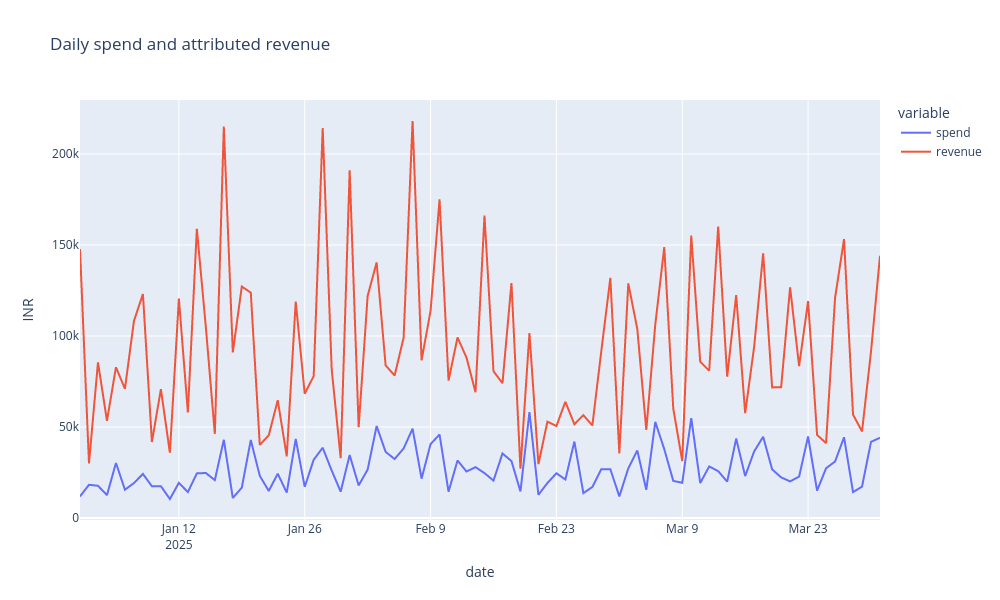

In [16]:
# A list of two y columns produces two named lines on the same value axis.
fig = px.line(
    daily, x="date", y=["spend", "revenue"],
    title="Daily spend and attributed revenue", labels={"value": "INR"},
)
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

Both lines are monetary totals in INR. Their difference is not net profit because product/service costs and other expenses are missing. Attributed sales may reflect a delay or an attribution rule the CSV does not explain. The chart reveals timing and scale to investigate; it does not prove that a higher spend caused that day's revenue. Hover in the interactive version supplies the exact grouped values.

### Step 15 - Plot aggregate channel ROAS with scale in hover details

**Question:** Which selected channel reports the highest efficiency, and at what scale?

channel  ROAS     spend  conversions  CTR_pct
Display  4.00 645963.35         3391     4.37
  Email  3.15 627985.17         2837     4.00
 Search  3.38 558090.56         2701     4.37
 Social  3.16 599674.85         2705     4.14


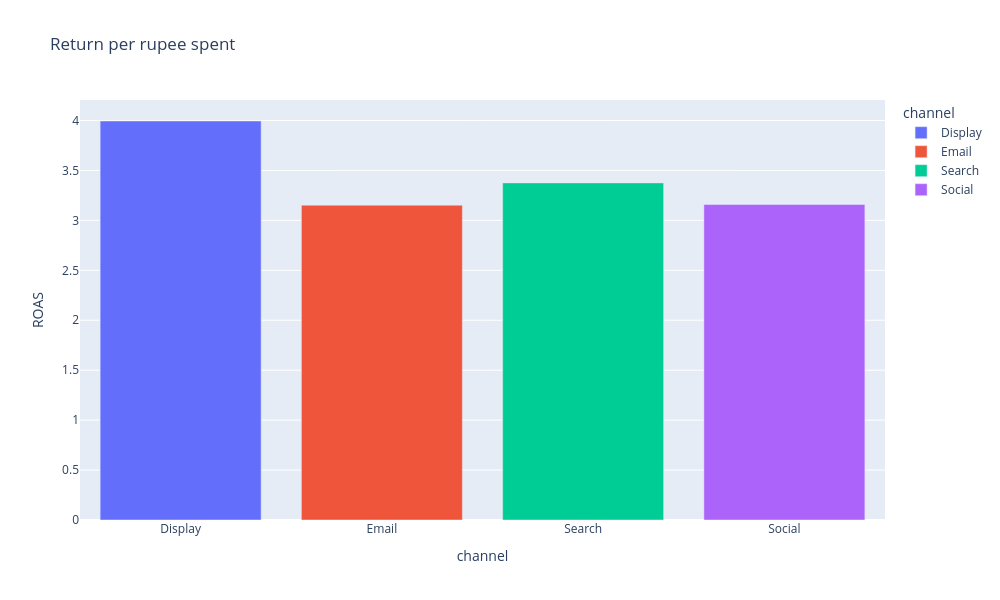

In [17]:
# Reset the channel index into a normal column for Plotly's x argument.
channels = channel_summary.reset_index().rename(columns={"roas": "ROAS"})
channels["CTR_pct"] = 100 * channels["clicks"].div(
    channels["impressions"].replace(0, float("nan"))
)
print(channels[["channel", "ROAS", "spend", "conversions", "CTR_pct"]]
      .round(2).to_string(index=False))

fig = px.bar(
    channels, x="channel", y="ROAS", color="channel",
    title="Return per rupee spent", hover_data=["spend", "conversions", "CTR_pct"],
)
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

The bar height is a multiple, not an INR amount. The supporting table and live hover data keep spend and conversion scale visible. `CTR_pct` is already multiplied by 100, so a value near 4 means about 4%, while the earlier `ctr` variable is a fraction near 0.04. Formatting an already-multiplied value with Python's `%` format would multiply it again. The original app creates a separate grouped `channels` table with the same information; it does not add these ratios to each selected source row.

### Step 16 - Plot the distribution of spend per observation

**Question:** Is the budget spread evenly or concentrated in large observations?

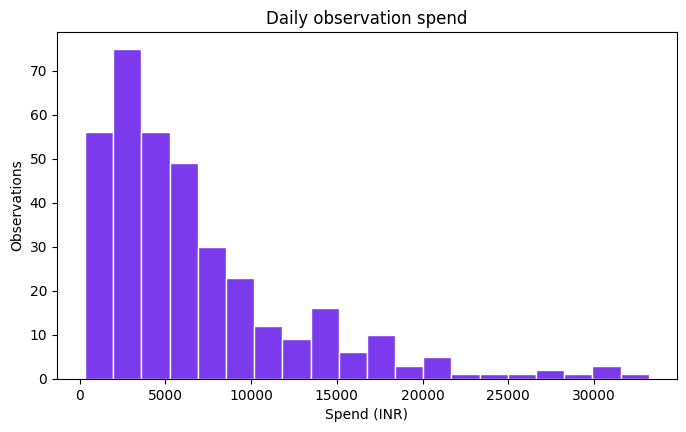

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
# Use raw selected observation spend, not the daily aggregate table.
ax.hist(filtered["spend"], bins=20, color="#7c3aed", edgecolor="white")
ax.set(title="Daily observation spend", xlabel="Spend (INR)", ylabel="Observations")
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

Each bin counts channel/campaign-day records whose spend falls in a monetary range. It is not a count of customers or complete daily company budgets. The right tail helps explain why an average can differ from the median. Twenty bins is a chosen setting; changing it changes the appearance, not the source totals. The app renders the figure with `st.pyplot(fig)` and closes the Matplotlib handle afterward to avoid retaining figures across reruns.

### Step 17 - Compare conversion-count distributions by channel

**Question:** Which channel tends to bring more conversions per observation, and how variable is that count?

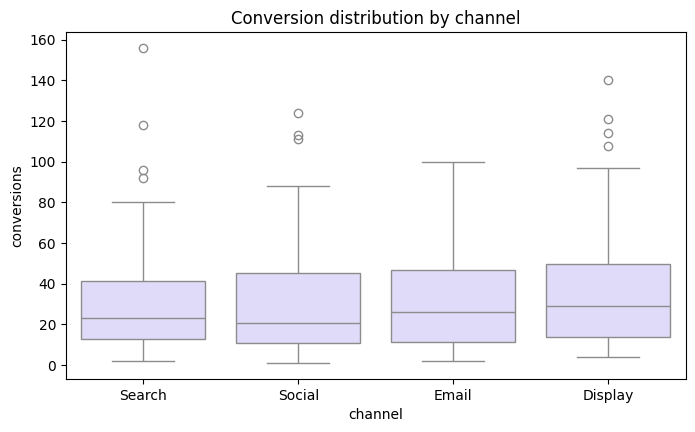

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
# Seaborn summarizes individual observations within each channel.
sns.boxplot(data=filtered, x="channel", y="conversions", ax=ax, color="#ddd6fe")
ax.set_title("Conversion distribution by channel")
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

The middle line is the median, the box spans the middle 50%, and default whiskers extend to observations within the 1.5-interquartile-range rule. Points beyond are observations to inspect, not automatically invalid records. The y-axis contains conversion counts, not conversion percentages. A channel may have larger counts because it received more spend or traffic. A taller box therefore does not by itself prove greater efficiency; also compare selected sample sizes.

### Step 18 - Inspect individual spend and revenue observations

**Question:** Which observations combine meaningful outcome volume with strong attributed revenue?

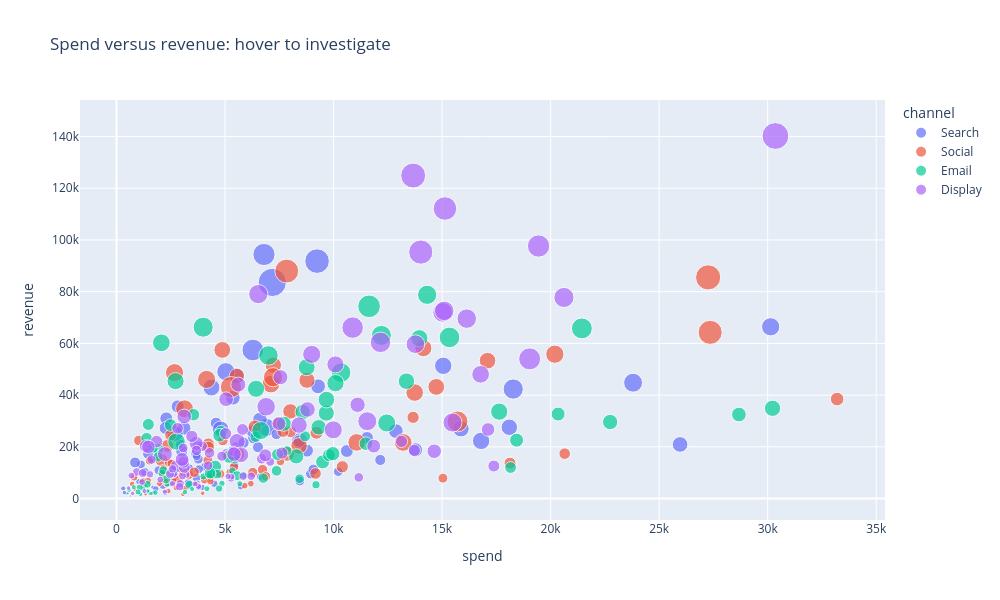

In [20]:
# Each point remains one selected source observation; no grouping is applied.
fig = px.scatter(
    filtered, x="spend", y="revenue", color="channel", size="conversions",
    hover_data=["campaign", "date"],
    title="Spend versus revenue: hover to investigate",
)
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

Position encodes spend and revenue, color identifies channel, and marker size represents conversion count. A point in the upper right is large in both cost and revenue; it is not necessarily best in revenue per rupee. A larger marker means more conversions, not a higher conversion rate. The app fits no regression line and computes no correlation coefficient for this view. Budget choice, audience differences and attribution rules can explain associations, so the plot cannot estimate the causal effect of an extra rupee of spend.

## Part 5 - Inspect, explain and export results

### Step 19 - Inspect the numeric summary and unusually large spend

**Question:** Which records should we investigate when the distribution has a long tail?

In [21]:
print(filtered.select_dtypes(include="number").describe().round(2).to_string())

# An extra inspection preserves rows instead of removing 'outliers' automatically.
largest = filtered.nlargest(3, "spend")
print("\nThree largest observation spends:")
print(largest[["date", "channel", "campaign", "spend", "revenue", "conversions"]]
      .to_string(index=False))
print(f"\nMedian observation spend: INR {filtered['spend'].median():,.2f}")

       impressions   clicks  conversions     spend    revenue
count       360.00   360.00       360.00    360.00     360.00
mean       9678.52   407.74        32.32   6754.76   23163.51
std        4498.77   272.87        26.57   5929.25   21818.73
min        1860.00    38.00         1.00    309.95     987.40
25%        5745.75   185.00        12.75   2652.34    8516.98
50%        9484.50   347.50        25.50   5031.50   16932.96
75%       13353.00   572.00        46.00   8773.02   29078.45
max       17845.00  1250.00       156.00  33200.45  140207.56

Three largest observation spends:
      date channel campaign    spend   revenue  conversions
2025-02-25  Social Seasonal 33200.45  38469.59           36
2025-02-07 Display   Launch 30356.72 140207.56          140
2025-02-06   Email   Launch 30223.57  34902.47           52

Median observation spend: INR 5,031.51


**Interpretation and reasoning**

`describe()` reports count, mean, standard deviation, extremes and quartiles; its 50% row is the median. Counts and monetary amounts have different units, so their spreads are not directly comparable. The three-largest-spend table is an additional inspection using actual selected rows. It does not remove those rows or claim they are errors. The median is per observation, not median total company-day spend.

### Step 20 - Observe empty selections and undefined ratios

**Question:** When is zero a programming fallback rather than a meaningful business rate?

In [22]:
no_channels = frame[frame["channel"].isin([])]
print("Observations after selecting no channels:", len(no_channels))

# These explicit edge-case values are separate from the bundled CSV.
print("Scalar ratio(100, 0) fallback:", ratio(100, 0))
example_conversions = 0
example_spend = 100
print("CPA display with no conversions:",
      f"{ratio(example_spend, example_conversions):.2f}" if example_conversions else "N/A")
undefined_roas = pd.Series([100.0]).div(pd.Series([0.0]).replace(0, float("nan")))
print("Grouped ROAS with zero spend:", undefined_roas.iloc[0])

Observations after selecting no channels: 0
Scalar ratio(100, 0) fallback: 0.0
CPA display with no conversions: N/A
Grouped ROAS with zero spend: nan


**Interpretation and reasoning**

The source stops an empty selection. Its scalar helper returns zero for a zero denominator, but mathematically those rates are undefined. CPA explicitly shows N/A when conversion count is zero, avoiding the implication of free acquisition. Grouped rates use NaN. If all groups have undefined ROAS, the original `idxmax()`/leader-text path is unguarded. With zero conversions across all groups, a named volume leader can simply be the first member of a zero-valued tie.

### Step 21 - Describe the exact analysis scope

**Question:** What does a rate or leader statement actually refer to?

In [23]:
scope_parts = []
# Low-cardinality labels make useful report context without long ID lists.
for column in frame.select_dtypes(include="object").columns:
    if frame[column].nunique() <= 12:
        labels = ", ".join(map(str, sorted(filtered[column].unique())))
        scope_parts.append(column.replace("_", " ") + ": " + labels)
scope_parts.append(
    f"Observed records: {filtered['date'].min():%Y-%m-%d} "
    f"to {filtered['date'].max():%Y-%m-%d}"
)
scope_parts.append(f"Requested dates: {dates[0]} to {dates[1]} (inclusive)")
scope = "; ".join(scope_parts)
print(scope)

channel: Display, Email, Search, Social; campaign: Always on, Launch, Seasonal; Observed records: 2025-01-01 to 2025-03-31; Requested dates: 2025-01-01 to 2025-03-31 (inclusive)


**Interpretation and reasoning**

A reported ratio needs its channels, campaigns and period. This follows the original app's scope pattern. Requested dates describe the control; observed dates describe the rows that survived. They can differ if a selected boundary has no observation. This text is useful context, but it is not a copy of the source dataset or a complete serialized record that guarantees identical results after the CSV is edited.

### Step 22 - Generate answer sentences from calculated values

**Question:** How does the report update its conclusions when a filter changes?

In [24]:
# Reuse measured variables instead of manually typing results into prose.
insights = [
    ("What attributed return is represented?",
     f"INR {spend:,.2f} spend and INR {revenue:,.2f} revenue produce {roas:.2f}x ROAS."),
    ("How well does traffic convert?",
     f"{impressions:,} impressions, {clicks:,} clicks and {conversions:,} conversions; "
     f"CTR {ctr:.2%}, conversion rate {conversion_rate:.2%}."),
    ("Which channel leads reported efficiency?",
     f"{best_channel}: {channel_summary.loc[best_channel, 'roas']:.2f}x ROAS on "
     f"INR {channel_summary.loc[best_channel, 'spend']:,.2f} spend."),
    ("Which channel leads conversion volume?",
     f"{volume_channel}: {channel_summary.loc[volume_channel, 'conversions']:,.0f} conversions."),
    ("What is each attributed conversion costing?",
     f"INR {cpa:,.2f}." if conversions else "Undefined because there are no conversions."),
    ("How concentrated is observation spend?",
     f"Median INR {filtered['spend'].median():,.2f}; maximum INR {filtered['spend'].max():,.2f}."),
]
for question, answer in insights:
    print(question)
    print(answer)
    print()

What attributed return is represented?
INR 2,431,713.93 spend and INR 8,338,864.84 revenue produce 3.43x ROAS.

How well does traffic convert?
3,484,268 impressions, 146,788 clicks and 11,634 conversions; CTR 4.21%, conversion rate 7.93%.

Which channel leads reported efficiency?
Display: 4.00x ROAS on INR 645,963.35 spend.

Which channel leads conversion volume?
Display: 3,391 conversions.

What is each attributed conversion costing?
INR 209.02.

How concentrated is observation spend?
Median INR 5,031.51; maximum INR 33,200.45.



**Interpretation and reasoning**

F-strings interpolate computed values into fixed explanatory sentences. `.loc[channel, field]` retrieves the relevant grouped value by label. These shorter teaching sentences use the same facts as the source's fuller insights, which add cautions about attribution and scope. The original displays the first three in its short summary and all six in its report. There is no AI request here and no need for an API key. A leader label must still be interpreted with sample size, scale and possible ties.

### Step 23 - Keep field meanings alongside the calculations

**Question:** How can another reader interpret the same column names correctly?

In [25]:
# Map source field names to business meanings so each result retains its units and row grain.
field_guide = {
    "date": "One observation date",
    "channel": "Channel receiving attributed results",
    "campaign": "Campaign label within the observations",
    "impressions": "Ad-display events, not unique people",
    "clicks": "Recorded clicks, not unique visitors",
    "conversions": "Attributed conversion events",
    "spend": "Advertising cost in INR",
    "revenue": "Attributed sales in INR, not profit or proven incrementality",
}
print(pd.DataFrame(field_guide.items(), columns=["Field", "Meaning"]).to_string(index=False))

      Field                                                      Meaning
       date                                         One observation date
    channel                         Channel receiving attributed results
   campaign                       Campaign label within the observations
impressions                         Ad-display events, not unique people
     clicks                         Recorded clicks, not unique visitors
conversions                                 Attributed conversion events
      spend                                      Advertising cost in INR
    revenue Attributed sales in INR, not profit or proven incrementality


**Interpretation and reasoning**

A dictionary maps exact source names to explanations; `.items()` supplies pairs that pandas can render as a table. The original stores and reuses these meanings in `FIELD_GUIDE`. For a real project, agree on the conversion event, currency and attribution window before trusting comparisons. A label such as `conversions` cannot reveal whether outcomes are purchases, registrations or leads without its data definition.

### Checkpoint - Review the decision language

Choose a channel finding and inspect its spending and conversion volume. Would you recommend a controlled investigation or claim a guaranteed return? Explain what the report must include so a reader can distinguish an observed attribution ratio from a causal or profit claim.

### Step 24 - Assemble a compact Markdown report

**Question:** How does ordinary Python produce a Markdown report?

In [26]:
kpi_values = [
    ("Ad spend (INR)", f"{spend:,.2f}"),
    ("Attributed revenue (INR)", f"{revenue:,.2f}"),
    ("ROAS", f"{roas:.2f}x"),
    ("Cost per conversion (INR)", f"{cpa:,.2f}" if conversions else "N/A"),
    ("Conversion rate", f"{conversion_rate:.2%}"),
]
report_parts = [
    "# Marketing campaigns - teaching report",
    "## Business question\nWhich channel/campaign combinations merit further investigation?",
    "## Scope\n" + scope,
    "## KPI results\n| Measure | Result |\n| --- | --- |\n"
    + "\n".join(f"| {name} | {value} |" for name, value in kpi_values),
    "## Questions answered\n"
    + "\n\n".join(f"### {question}\n{answer}" for question, answer in insights),
    "## Source fields\n| Field | Meaning |\n| --- | --- |\n"
    + "\n".join(f"| {name} | {meaning} |" for name, meaning in field_guide.items()),
    "## Limits\nFictional attributed observations. No customer deduplication, margin, "
    "lifetime value or experiment assignment. ROAS is not profit or a causal effect.",
]
full_report = "\n\n".join(report_parts)

# Show an executed excerpt while retaining the complete string for download.
print("\n".join(full_report.splitlines()[:24]))
print("\n[Preview ends; full_report contains the remaining sections.]")

# Marketing campaigns - teaching report

## Business question
Which channel/campaign combinations merit further investigation?

## Scope
channel: Display, Email, Search, Social; campaign: Always on, Launch, Seasonal; Observed records: 2025-01-01 to 2025-03-31; Requested dates: 2025-01-01 to 2025-03-31 (inclusive)

## KPI results
| Measure | Result |
| --- | --- |
| Ad spend (INR) | 2,431,713.93 |
| Attributed revenue (INR) | 8,338,864.84 |
| ROAS | 3.43x |
| Cost per conversion (INR) | 209.02 |
| Conversion rate | 7.93% |

## Questions answered
### What attributed return is represented?
INR 2,431,713.93 spend and INR 8,338,864.84 revenue produce 3.43x ROAS.

### How well does traffic convert?
3,484,268 impressions, 146,788 clicks and 11,634 conversions; CTR 4.21%, conversion rate 7.93%.


[Preview ends; full_report contains the remaining sections.]


**Interpretation and reasoning**

The report is text assembled from lists, f-strings and `join()`. Newline characters create sections, and pipes create table columns. The output is an actual excerpt of this shorter teaching report. The existing app builds 12 sections, including all visual guides, quality information, recommendations and limitations, using the same technique. Its report contains five KPI rows because attributed revenue appears there even though the top row has only four cards. Its field dictionary is appended to list index 5, the KPI-results section because the report title occupies index zero.

### Step 25 - Preview the selected CSV export and distinguish it from the summary

**Question:** Does the existing CSV download contain channel ROAS?

In [27]:
# Serialize selected source observations, excluding the pandas row index.
csv_text = filtered.to_csv(index=False)
print("\n".join(csv_text.splitlines()[:4]))
print(f"\nFiltered export: {len(filtered)} rows x {len(filtered.columns)} columns")
print("Filtered fields:", ", ".join(filtered.columns))
print("Grouped table fields:", ", ".join(channels.columns))

date,channel,campaign,impressions,clicks,conversions,spend,revenue
2025-01-01,Search,Seasonal,14074,984,96,6793.68,94378.06
2025-01-01,Social,Launch,17118,501,33,2065.35,14977.08
2025-01-01,Email,Seasonal,9956,254,26,1385.1,23334.97

Filtered export: 360 rows x 8 columns
Filtered fields: date, channel, campaign, impressions, clicks, conversions, spend, revenue
Grouped table fields: channel, spend, revenue, clicks, impressions, conversions, ROAS, CTR_pct


**Interpretation and reasoning**

No. `filtered` still has the eight source fields, whereas `ROAS` and `CTR_pct` belong to the separate grouped `channels` table. The first download row is one observation; a grouped-table row is one channel. A future download of `channels.to_csv(index=False)` would be a separate summary export. This cell creates text in memory and does not alter the original CSV. In Streamlit the button sends that text to the browser.

## Part 6 - Build the separate Streamlit interface

Pandas already answers the questions. Streamlit makes those answers usable by a reader who should not need to edit code to change the selection. Its widget calls return Python values that feed the filters; its display calls render values and figures already calculated by the analysis.

Copy only the Python code inside the **Complete Streamlit teaching script** reference block below as `practice_app.py` beside `marketing_campaigns.csv`, then run:

```bash
python -m streamlit run practice_app.py
```

If the prepared Cloud Lab dashboard already uses port 8501, append `--server.port 8502` and open that forwarded port. Run the fuller existing project by using `app.py` instead of `practice_app.py` in the command.

A normal widget change reruns the script top to bottom. The current lists and date interval are returned by the widgets and reused in pandas masks. An incomplete date interval or empty selection stops before calculations. The CSV is deliberately read on every run; a saved file edit appears on the next rerun, not through a promised automatic CSV watcher.

The `with` blocks determine output placement, not data filtering. In Streamlit 1.50 all tab contents execute on a full rerun, even when hidden, and collapsing an expander does not make its code lazy. Table sorting, chart hover/zoom and switching tabs do not change the underlying analytical population in this app.

This teaching reconstruction contains the same four metrics and five chart types but shorter explanatory text and a shorter report. Its explicit guard for entirely undefined channel ROAS is a labeled improvement; the original leader path does not contain it. Nothing here rewrites the existing app or dataset.

### Step 26 - Build the separate interactive marketing teaching app

**Question:** How can a reader explore the same calculations without editing Python?

## Connect notebook state to the existing marketing app

Compare these objects with [app.py](app.py). The notebook exposes intermediate tables; the original app adds the fuller context and report documented in [EXPLANATION.md](EXPLANATION.md).

| Notebook evidence | Existing app component | Why the connection matters |
| --- | --- | --- |
| `selected_channels`, `selected_campaigns`, `dates` | Sidebar `selected_channel`, `selected_campaign` and date widgets | Widgets supply the choices that the notebook assigns directly |
| Selected totals and ratios | Ad spend, ROAS, acquisition-cost and conversion-rate cards | Each card is calculated for the same retained observations |
| `daily` | Daily spend/revenue line chart in **Campaign dashboard** | One point summarizes a selected date |
| `channel_summary` and `channels` | Channel ROAS bar chart and grouped table | Efficiency remains connected to spend, conversions and CTR |
| `filtered` | Spend histogram, conversion boxplot and spend/revenue scatter | These views retain observation-level variation |
| Scope, `insights` and `full_report` | **Full report** and Markdown download | A finding is exported with its scope and assumptions |

The report's KPI table also includes attributed revenue, even though it is not one of the four headline cards. The filtered CSV contains the eight source fields; aggregate ratios belong to summary tables. **Data and quality** lets readers inspect selected records and numeric summaries, while its source-quality counts describe the full `frame`.

Changing a sidebar widget reruns the script with its current values. The uncached loader reads the CSV on that next run; a CSV edit does not itself guarantee a refresh. Incomplete dates or an empty selection stop the run before calculations. Streamlit 1.50 computes all tab bodies, including hidden ones, and explicit rendering calls display the figures. The browser does not require the learner to execute each downstream cell manually.

Runnable AppTest cells inspect the sibling app and demonstrate a real filter rerun without starting a server. The complete teaching script remains a Markdown reference; save it separately to run Streamlit in a browser.

### Complete Streamlit teaching script - reference

The following complete script is shown in a **Markdown reference cell**. It is intended for the separate `.py` file described above, because Streamlit renders controls and pages through its own server execution. The analysis cells in this notebook have already calculated and explained the measures used here.

```python
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import streamlit as st

st.set_page_config(page_title="Marketing Campaign Lab", layout="wide")
st.title("Marketing Campaign Lab")
st.caption("Teaching reconstruction | Fictional attributed data | Currency: INR")

# Locate the CSV beside this standalone Python file.
data_file = Path(__file__).resolve().with_name("marketing_campaigns.csv")
required = ["date", "channel", "campaign", "impressions", "clicks", "conversions", "spend", "revenue"]
try:
    frame = pd.read_csv(data_file)
    if not set(required).issubset(frame.columns) or frame.empty:
        raise ValueError("Provide a nonempty CSV with all required columns.")
    frame["date"] = pd.to_datetime(frame["date"], errors="raise")
    for column in ["impressions", "clicks", "conversions", "spend", "revenue"]:
        frame[column] = pd.to_numeric(frame[column], errors="raise")
    if frame[required].isna().any().any():
        raise ValueError("Fill missing required values first.")
except (OSError, ValueError, KeyError) as error:
    st.error(str(error))
    st.stop()

def ratio(numerator, denominator):
    return numerator / denominator if denominator else 0.0

# Widget values become ordinary Python inputs to the same pandas analysis.
selected_channels = st.sidebar.multiselect(
    "Channels", sorted(frame["channel"].unique()), default=sorted(frame["channel"].unique()),
)
selected_campaigns = st.sidebar.multiselect(
    "Campaigns", sorted(frame["campaign"].unique()), default=sorted(frame["campaign"].unique()),
)
dates = st.sidebar.date_input(
    "Date range", (frame["date"].min().date(), frame["date"].max().date()),
    min_value=frame["date"].min().date(), max_value=frame["date"].max().date(),
)
if len(dates) != 2:
    st.info("Choose both a start and an end date.")
    st.stop()
filtered = frame[frame["channel"].isin(selected_channels) & frame["campaign"].isin(selected_campaigns)].copy()
filtered = filtered[filtered["date"].dt.date.between(dates[0], dates[1])]
if filtered.empty:
    st.info("No observations match. Restore a selection or widen the dates.")
    st.stop()

# Aggregate first so every rate is weighted by the appropriate denominator.
spend = filtered["spend"].sum()
revenue = filtered["revenue"].sum()
conversions = filtered["conversions"].sum()
clicks = filtered["clicks"].sum()
cards = st.columns(4)
cards[0].metric("Ad spend (INR)", f"{spend:,.0f}")
cards[1].metric("ROAS", f"{ratio(revenue, spend):.2f}x")
cards[2].metric("Cost per acquisition (INR)", f"{ratio(spend, conversions):,.0f}" if conversions else "N/A")
cards[3].metric("Conversion rate", f"{ratio(conversions, clicks):.1%}")

channels = filtered.groupby("channel", as_index=False)[[
    "impressions", "clicks", "conversions", "spend", "revenue"
]].sum()
channels["ROAS"] = channels["revenue"].div(channels["spend"].replace(0, float("nan")))
channels["CTR_pct"] = 100 * channels["clicks"].div(channels["impressions"].replace(0, float("nan")))
valid_rates = channels.dropna(subset=["ROAS"])
# Teaching improvement: handle all channel rates being undefined explicitly.
leader = valid_rates.loc[valid_rates["ROAS"].idxmax(), "channel"] if not valid_rates.empty else "Undefined"

dashboard, explore, data_tab, report_tab = st.tabs(["Dashboard", "Explore", "Data", "Report"])
with dashboard:
    daily = filtered.groupby("date", as_index=False)[["spend", "revenue"]].sum()
    st.plotly_chart(px.line(daily, x="date", y=["spend", "revenue"],
                           title="Daily spend and attributed revenue"), use_container_width=True)
    st.plotly_chart(px.bar(channels, x="channel", y="ROAS", color="channel",
                          hover_data=["spend", "conversions", "CTR_pct"],
                          title="Return per rupee spent"), use_container_width=True)
    st.dataframe(channels.round(2), hide_index=True, width="stretch")
with explore:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(filtered["spend"], bins=20, color="#7c3aed", edgecolor="white")
    ax.set(title="Observation spend distribution", xlabel="Spend (INR)", ylabel="Observations")
    st.pyplot(fig)
    plt.close(fig)  # Release the Matplotlib figure after rendering.

    fig, ax = plt.subplots(figsize=(8, 4))
    sns.boxplot(data=filtered, x="channel", y="conversions", ax=ax, color="#ddd6fe")
    ax.set_title("Conversion distribution by channel")
    st.pyplot(fig)
    plt.close(fig)

    st.plotly_chart(px.scatter(filtered, x="spend", y="revenue", color="channel", size="conversions",
                              hover_data=["campaign", "date"], title="Spend versus attributed revenue"),
                    use_container_width=True)
with data_tab:
    # Export the selected observations; grouped rates are in channels instead.
    st.dataframe(filtered, hide_index=True, width="stretch")
    st.download_button("Download filtered CSV", filtered.to_csv(index=False),
                       "filtered_marketing_campaigns.csv", "text/csv")
with report_tab:
    report_parts = [
        "# Marketing campaigns - teaching report",
        f"Selected {len(filtered)} observations, {dates[0]} to {dates[1]}.",
        f"Channels: {', '.join(selected_channels)}. Campaigns: {', '.join(selected_campaigns)}.",
        f"Ad spend: INR {spend:,.2f}. Attributed revenue: INR {revenue:,.2f}.",
        f"ROAS: {ratio(revenue, spend):.2f}x. Highest defined channel ROAS: {leader}.",
        "Fictional attribution data. ROAS is not profit and does not prove a causal budget response.",
    ]
    report = "\n\n".join(report_parts)
    st.markdown(report)
    st.download_button("Download teaching report", report, "marketing_teaching_report.md", "text/markdown")
```

## Inspect the actual Streamlit application from this notebook

The companion script above is a compact teaching reconstruction. The next executable cells inspect the **existing sibling `app.py`**, which also contains the complete business context, chart explanations and full report.

`AppTest` is Streamlit's testing interface. It runs the application and lets Python inspect the UI elements it produced. It does not start a browser server. We use it here to connect the notebook's calculations with the application's real labels and values. The displayed tables summarize application elements; they are not browser screenshots.

### Load and run the sibling app

`AppTest.from_file(...)` reads a saved Streamlit script; `.run()` executes it with default widget values. The checks stop this cell if the app raises an exception or displays a loading error. Keeping `app.py` beside its CSV lets its `Path(__file__)` lookup work independently of notebook variables.

In [28]:
from streamlit.testing.v1 import AppTest  # Inspect Streamlit output without launching a server.
import logging

# AppTest intentionally runs without a browser session; quiet its context-only warning.
# Application errors are still checked explicitly below.
logging.getLogger('streamlit.runtime.scriptrunner_utils.script_run_context').setLevel(logging.ERROR)

app_file = PROJECT_DIR / 'app.py'
app_preview = AppTest.from_file(str(app_file), default_timeout=45).run()
if len(app_preview.exception):
    raise RuntimeError('; '.join(str(error.value) for error in app_preview.exception))
if len(app_preview.error):
    raise RuntimeError('; '.join(str(error.value) for error in app_preview.error))

print('Script:', app_file.name)
print('Title:', app_preview.title[0].value)
print('Default application run completed.')

Script: app.py
Title: Marketing Campaign Lab
Default application run completed.


### Read the controls, KPI cards and output containers

The values below come from the application instance that just ran. A metric element has a `label` and a formatted `value`; a multiselect has the current list of choices. The table dimensions describe what the app actually rendered. Chart counts distinguish interactive Plotly figures from Matplotlib/Seaborn images.

In [29]:
# Turn rendered KPI cards into an ordinary table we can inspect in the notebook.
baseline_cards = {metric.label: metric.value for metric in app_preview.metric}
display(pd.DataFrame(baseline_cards.items(), columns=['Dashboard measure', 'Displayed value']))

for widget in app_preview.multiselect:
    print(widget.label + ': ' + ', '.join(map(str, widget.value)))
for widget in app_preview.date_input:
    print(widget.label + ': ' + ' to '.join(map(str, widget.value)))
for widget in app_preview.slider:
    print(widget.label + ': ' + str(widget.value))
for index, table in enumerate(app_preview.dataframe, start=1):
    print(f'Table {index}: {len(table.value)} rows x {len(table.value.columns)} columns')
print('Interactive Plotly charts:', len(app_preview.get('plotly_chart')))
print('Rendered statistical charts:', len(app_preview.get('imgs')))
for button in app_preview.get('download_button'):
    print('Download:', button.proto.label)

,Dashboard measure,Displayed value
0,Ad spend (INR),"2,431,714"
1,ROAS,3.43x
2,Cost per acquisition (INR),209
3,Conversion rate,7.9%


Channels: Display, Email, Search, Social
Campaigns: Always on, Launch, Seasonal
Date range: 2025-01-01 to 2025-03-31
Table 1: 5 rows x 3 columns
Table 2: 4 rows x 8 columns
Table 3: 8 rows x 2 columns
Table 4: 360 rows x 8 columns
Table 5: 8 rows x 5 columns
Table 6: 8 rows x 3 columns
Interactive Plotly charts: 3
Rendered statistical charts: 2
Download: Download filtered CSV
Download: Download full report (Markdown)


### Change one filter and observe a real app rerun

This cell selects one value in the first multiselect and compares the resulting KPI cards with the baseline. `.set_value(...)` changes the control; `.run()` executes the app again. We then restore the complete selection so the preview ends in its default state.

The notebook's own `frame` and `filtered` variables belong to the analysis session. `AppTest` executes the script in its own application context, so changing this preview does not silently alter the earlier notebook analysis. In the live browser app, the corresponding widget interaction triggers the rerun for you.

In [30]:
# Keep all original choices so the application can be restored after this experiment.
first_control = app_preview.multiselect[0]
original_choices = list(first_control.value)
one_choice = original_choices[0]
control_label = first_control.label

# This is the programmatic equivalent of narrowing a sidebar multiselect.
first_control.set_value([one_choice]).run()
if len(app_preview.exception) or len(app_preview.error):
    raise RuntimeError('The narrowed app selection did not complete successfully.')
selected_cards = {metric.label: metric.value for metric in app_preview.metric}
comparison = pd.DataFrame({
    'Dashboard measure': list(baseline_cards),
    'All choices': list(baseline_cards.values()),
    f'{control_label}: {one_choice}': [selected_cards[label] for label in baseline_cards],
})
display(comparison)

# Restore the baseline; the notebook data and the source CSV have not been edited.
app_preview.multiselect[0].set_value(original_choices).run()
if len(app_preview.exception) or len(app_preview.error):
    raise RuntimeError('The application could not restore its original selection.')
print('Restored', control_label + ':', ', '.join(map(str, original_choices)))

,Dashboard measure,All choices,Channels: Display
0,Ad spend (INR),"2,431,714","645,963"
1,ROAS,3.43x,4.00x
2,Cost per acquisition (INR),209,190
3,Conversion rate,7.9%,8.6%


Restored Channels: Display, Email, Search, Social


### Open the browser interface

In a **terminal in this project folder**, run:

```bash
python -m streamlit run app.py --server.port 8502
```

Open the displayed local URL, or forward port 8502 in Cloud Labs. The built-in workshop dashboard uses port 8501. Streamlit keeps running while the page is available; stop it with **Ctrl+C** in that terminal. This command is a terminal instruction, so **Run All** in this notebook does not start the server.

Follow one choice through the app: widget value → pandas row selection → derived columns → grouped results → cards/charts/report. This is the connection between the analysis and its browser interface.

## Limits, troubleshooting and useful practice

The loader checks required fields, a nonempty CSV, parseable dates/numbers and nonmissing essential cells. It does not enforce nonnegative integer counts, finite amounts, a unique business observation key, or the convention `conversions <= clicks <= impressions`. Whether that funnel convention applies to a real source depends on its event definitions. Exact duplicates are reported, not automatically removed. Negative conversions can parse successfully and later fail when used as scatter marker sizes; the loading error handler does not cover the whole application.

The scalar ratio helper uses zero as a fallback for zero denominators; CPA explicitly reports N/A with zero conversions. Grouped ROAS uses NaN for zero spend. The existing all-undefined-channel leader path is unguarded, while the final teaching reconstruction labels its added guard. Ties can name the first maximum in sorted group order rather than a unique winner. Strong filtering can reduce the evidence to very few observations.

No customer deduplication, lifetime value, product margin, refunds, causal experiment, confidence interval or budget-response model is present. A high bar cannot establish how a channel will perform with additional spend. Revenue minus advertising cost alone would still omit other costs and would not establish incrementality. Useful reporting states the scope, denominator, scale and unresolved question.

| If you see this | What to check |
| --- | --- |
| A missing-library error | Activate the intended Python environment and install using its `python -m pip`. |
| Notebook cannot find the CSV | Start it inside `02_marketing_campaigns`; notebook cells use that working directory. |
| The app cannot find the CSV | Keep the exact named file beside the Python script, which resolves its own location. |
| Numeric/date conversion fails | Inspect edited values and headers. The app intentionally rejects invalid inputs instead of silently discarding them. |
| No rows match | Re-enable channels/campaigns or widen the interval. Conditions combine as AND. |
| CPA is N/A | No selected conversions exist; cost per conversion is undefined, not zero cost. |
| A zero ratio seems suspicious | Inspect its denominator because some scalar displays use a fallback. |
| Downloaded observations have no ROAS column | The existing download exports `filtered`; grouped rates belong to `channels`. |
| Histogram totals differ from the daily line chart | The histogram counts observations; the line chart aggregates amounts by date. Their grains differ intentionally. |
| Cards and reports show different digits | Compare formatting: cards round some amounts to whole INR and conversion rate to one decimal percentage. |
| Saved CSV changes are not visible | Save and trigger a rerun; no automatic CSV watcher is implied by an uncached read. |

For practice, change the analysis selection to one campaign and rerun every subsequent cell. Compare the ROAS and conversion-volume leaders with their spend and counts. Investigate a high-revenue observation by its date/campaign before considering an exclusion; an unusually large result is not automatically an error. To add CTR to the interface, display the already calculated fractional CTR with `:.2%` after calculating it. To export channel summaries, create a separate button for `channels.to_csv(index=False)` and label its different row grain clearly.

This Markdown guide describes the method and shows executed baseline outputs. The app's Markdown report is rebuilt for current runtime filters. Neither is a reason to substitute a static screenshot's values for the current selected data.

## Sources

- [Existing project source](app.py), [bundled CSV](marketing_campaigns.csv), [workshop README](../README.md) and [repository README](../../README.md) ground the implemented behavior and executed outputs.
- [pandas 2.2 introduction](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/10min.html), [GroupBy guide](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/groupby.html) and [indexing guide](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/indexing.html) explain tabular operations.
- [Streamlit main concepts](https://docs.streamlit.io/get-started/fundamentals/main-concepts), [run instructions](https://docs.streamlit.io/develop/concepts/architecture/run-your-app) and [Streamlit 1.50 tabs](https://docs.streamlit.io/1.50.0/develop/api-reference/layout/st.tabs) explain the execution model.
- [Plotly Express](https://plotly.com/python/plotly-express/), [Matplotlib histogram](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hist.html), [Matplotlib close](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.close.html) and [Seaborn boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html) explain the visual functions used here.

## Practice explaining a changed result

1. **Restrict the analysis to one campaign label.** Rerun the dependent cells and compare the ROAS leader with the conversion-volume leader. Hint: inspect the spend supporting both rankings. What would you need to learn before moving budget between them?
2. **Investigate a strong date.** Inspect its individual observations and compare an equivalent nearby date window. Hint: keep channel and campaign choices consistent, and retain unusual observations while investigating them. Does the apparent advantage persist, and could the mix of activity explain part of it?
3. **Explain two different averages.** Revisit the existing observation-rate comparison. Hint: identify the denominator supplying each weight before looking at the answer. Which question does an equally weighted observation mean answer, and which does a ratio of totals answer?

Restore the initial selection and rerun the analysis when you want outputs that match the baseline lesson.

### Explanation checklist

State the observation grain, selection, metric units, numerator and denominator. Identify whether a chart uses observations, channel totals or daily totals. Include scale alongside efficiency. Explain undefined denominators before interpreting a fallback value. Distinguish attributed results from incremental effects, and name the missing cost or customer evidence required for a profit or acquisition decision.

## Finish with an explanation you can defend

Before presenting the project, explain one complete chain in your own words: **the question, the source rows, the operation, the result, and the decision it informs**. State the units and denominator. Show a supporting table or chart and one limitation. Then restart the kernel and run the notebook from the top to confirm that the result does not depend on forgotten interactive state.

Notebook and application references: [Jupyter notebook structure](https://nbformat.readthedocs.io/en/latest/format_description.html), [Plotly notebook renderers](https://plotly.com/python/renderers/), and [Streamlit 1.50 AppTest](https://docs.streamlit.io/1.50.0/develop/api-reference/app-testing/st.testing.v1.apptest).